# Stock Return Prediction

Predict next-session returns from daily prices and volume.

Asset IDs are pseudonyms.

**Main results**

- AR(5) lowers validation RMSE by about **0.6%** versus zero; zero has the lowest MAE.
- GARCH improves variance forecasts for asset_096, but not asset_478.
- Five selected stocks, one validation period. Price-adjustment issues remain; the test set is reserved.

**Task:** inspect the data and test whether price and volume history predicts the next session's return.

Forecast after the close:

$$y_{i,t}=r_{i,t+1}=C_{i,t+1}/C_{i,t}-1.$$

Use `daily_market_data.csv` (2013–2018). Prices are USD per share; volume is shares.

**Questions**

1. Why can price predictions have high $R^2$ while return predictions remain difficult?
2. Is dependence stronger in returns or their magnitudes?
3. Does volume add information?
4. Does pooling stocks help, and how should features be comparable?
5. Do complex models beat simple baselines?
6. Are results stable across stocks and time?

## 1. Data checks

Inspect the five-stock subset before cleaning. asset_476 is the focus for single-stock plots.

### Load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

stocks = ['asset_337', 'asset_476', 'asset_096', 'asset_478', 'asset_137']
focus_stock = 'asset_476'
colors = ['#2455a4', '#bb7916', '#7c3aed', '#0f766e', '#be185d']

plt.rcParams.update({
    'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .15
})

df = pd.read_csv('daily_market_data.csv')
df = df.loc[df['Name'].isin(stocks)].copy()
assert set(df['Name'].unique()) == set(stocks), 'A selected stock is missing.'

print('Stocks:', stocks)
print('Rows, columns:', df.shape)
display(df.head(3))

Stocks: ['asset_337', 'asset_476', 'asset_096', 'asset_478', 'asset_137']
Rows, columns: (6279, 7)


,date,open,high,low,close,volume,Name
114301,2013-02-08,20.16,20.4150,20.10,20.23,11809037,asset_096
114302,2013-02-11,20.17,20.2675,19.92,20.05,7734603,asset_096
114303,2013-02-12,20.07,20.2000,19.83,20.01,13505157,asset_096


### Sort and preserve the date grid

Keep the raw records and the union of source dates before removing any rows.

In [2]:
raw = df.copy()
price_cols = ['open', 'high', 'low', 'close']
value_cols = price_cols + ['volume']

df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['Name', 'date']).copy()
dates = pd.DatetimeIndex(df['date'].unique(), name='date').sort_values()

### Missing values

In [3]:
print('Missing values:')
display(df.isna().sum().to_frame('missing'))
display(df.loc[df.isna().any(axis=1)].head(5))

Missing values:


,missing
date,0
open,3
high,2
low,2
close,0
volume,0
Name,0


,date,open,high,low,close,volume,Name
165734,2015-07-17,NaN,88.76,88.24,88.72,2056819,asset_137
165857,2016-01-12,NaN,NaN,NaN,88.55,0,asset_137
581906,2015-05-12,NaN,NaN,NaN,124.08,569747,asset_476


### Coverage and duplicates

Equal row counts do not guarantee identical dates.

In [4]:
coverage = df.groupby('Name').agg(
    rows=('date', 'size'), distinct_dates=('date', 'nunique'),
    first_date=('date', 'min'), last_date=('date', 'max')
)
display(coverage.reindex(stocks))
print('Exact duplicates:', df.duplicated().sum())
print('Repeated stock/date:', df.duplicated(['Name', 'date']).sum())

,rows,distinct_dates,first_date,last_date
Name,,,,
asset_337,1259,1259,2013-02-08,2018-02-07
asset_476,1259,1259,2013-02-08,2018-02-07
asset_096,1259,1259,2013-02-08,2018-02-07
asset_478,1259,1259,2013-02-08,2018-02-07
asset_137,1243,1243,2013-02-08,2018-02-07


Exact duplicates: 0
Repeated stock/date: 0


### Compare date sets

Use asset_337's dates as the reference; count missing and extra dates for each stock.

In [5]:
reference_dates = set(df.loc[df['Name'] == 'asset_337', 'date'])
date_checks = []
for stock in stocks:
    stock_dates = set(df.loc[df['Name'] == stock, 'date'])
    date_checks.append({
        'stock': stock, 'same_dates_as_asset_337': stock_dates == reference_dates,
        'missing_vs_asset_337': len(reference_dates - stock_dates),
        'extra_vs_asset_337': len(stock_dates - reference_dates)
    })

date_alignment = pd.DataFrame(date_checks).set_index('stock')
display(date_alignment)
gap_dates = set(df.loc[df['Name'] == 'asset_137', 'date'])
missing_dates = sorted(reference_dates - gap_dates)
print('asset_137 missing dates:', len(missing_dates))
display(pd.DataFrame({'missing_asset_137_date': missing_dates}).head(5))

,same_dates_as_asset_337,missing_vs_asset_337,extra_vs_asset_337
stock,,,
asset_337,True,0,0
asset_476,True,0,0
asset_096,True,0,0
asset_478,True,0,0
asset_137,False,16,0


asset_137 missing dates: 16


,missing_asset_137_date
0,2013-04-26
1,2013-09-09
2,2013-09-10
3,2013-09-11
4,2014-06-10


asset_337, asset_476, asset_096 and asset_478 share **1,259 dates**. asset_137 has **16 missing dates**, including ten consecutive sessions in March 2015.

## 2. Cleaning and preparation

Remove exact duplicates; stop if distinct records share a stock-date key.

### Check numeric inputs

Require positive prices, nonnegative volume, finite values, and consistent OHLC bounds. Price ties are valid.

In [6]:
df = df.drop_duplicates().copy()
assert df[['Name', 'date']].notna().all().all(), 'Missing stock/date keys.'
assert not df.duplicated(['Name', 'date']).any(), 'Conflicting stock/date rows.'

checks = pd.DataFrame({
    'non-finite input': np.isinf(df[value_cols]).any(axis=1),
    'price <= 0': (df[price_cols] <= 0).any(axis=1),
    'volume < 0': df['volume'] < 0,
    'high is not highest': df['high'] < df[price_cols].max(axis=1),
    'low is not lowest': df['low'] > df[price_cols].min(axis=1)
})
display(checks.sum().to_frame('rows'))
display(df.loc[checks.any(axis=1)].head(5))

,rows
non-finite input,0
price <= 0,0
volume < 0,0
high is not highest,0
low is not lowest,2


,date,open,high,low,close,volume,Name
114650,2014-06-30,30.43,31.100,30.37,29.39,8132836,asset_096
165571,2014-11-06,78.47,81.305,80.49,81.26,1614419,asset_137


### Remove unusable rows

Drop missing or invalid OHLC/volume rows and retain them in `dropped_rows`. Keep zero volume and large, internally consistent observations.

In [7]:
missing_rows = df[value_cols].isna().any(axis=1)
invalid_rows = checks.any(axis=1)
dropped_rows = df.loc[missing_rows | invalid_rows].copy()
df = df.drop(index=dropped_rows.index)

print('Missing-input rows:', missing_rows.sum())
print('Invalid rows:', invalid_rows.sum())
print('Removed:', len(dropped_rows), '| Retained:', len(df))
print('Zero-volume rows retained:', df['volume'].eq(0).sum())
display(dropped_rows.head(5))
assert df[value_cols].notna().all().all()

Missing-input rows: 3
Invalid rows: 2
Removed: 5 | Retained: 6274
Zero-volume rows retained: 0


,date,open,high,low,close,volume,Name
114650,2014-06-30,30.43,31.100,30.37,29.39,8132836,asset_096
165571,2014-11-06,78.47,81.305,80.49,81.26,1614419,asset_137
165734,2015-07-17,NaN,88.760,88.24,88.72,2056819,asset_137
165857,2016-01-12,NaN,NaN,NaN,88.55,0,asset_137
581906,2015-05-12,NaN,NaN,NaN,124.08,569747,asset_476


### Align dates and calculate returns

Reindex before returns or lags. Keep gaps missing:

$$r_t=C_t/C_{t-1}-1.$$

`fill_method=None` prevents filling prices across a missing session.

In [8]:
close = df.pivot(index='date', columns='Name', values='close').reindex(dates)
volume = df.pivot(index='date', columns='Name', values='volume').reindex(dates)
returns = close.pct_change(fill_method=None)

In [9]:
display(close.head(3).round(2))

Name,asset_096,asset_137,asset_337,asset_476,asset_478
date,,,,,
2013-02-08,20.23,60.81,26.92,46.00,44.35
2013-02-11,20.05,60.68,26.94,45.70,44.32
2013-02-12,20.01,60.97,27.03,45.89,44.44


### Gaps after cleaning

Separate source gaps from removed rows and find each stock's longest missing run.

,source_gaps,rows_removed,clean_gaps,longest_gap
Name,,,,
asset_337,0,0,0,0
asset_476,0,1,1,1
asset_096,0,1,1,1
asset_478,0,0,0,0
asset_137,16,3,19,10


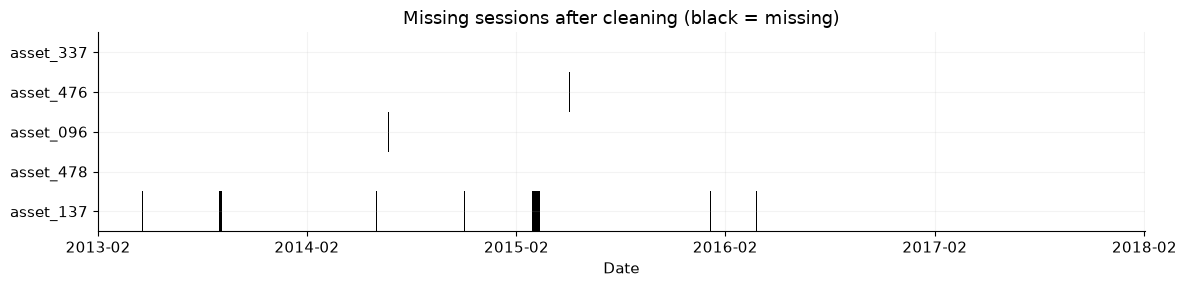

In [10]:
missing = close[stocks].isna()
source_counts = raw.groupby('Name').size()
clean_counts = df.groupby('Name').size()

gap_summary = pd.DataFrame({
    'source_gaps': len(dates) - source_counts,
    'rows_removed': source_counts - clean_counts,
    'clean_gaps': missing.sum()
}).reindex(stocks)

for name in stocks:
    # Each change between missing and present starts a new run.
    groups = missing[name].ne(missing[name].shift()).cumsum()
    gap_summary.loc[name, 'longest_gap'] = missing[name].groupby(groups).sum().max()
display(gap_summary.astype(int))

plt.figure(figsize=(12, 3))
plt.imshow(missing.T, aspect='auto', cmap='Greys', interpolation='nearest', vmin=0, vmax=1)
ticks = np.linspace(0, len(dates) - 1, 6, dtype=int)
plt.xticks(ticks, dates[ticks].strftime('%Y-%m'))
plt.yticks(range(len(stocks)), stocks)
plt.xlabel('Date')
plt.title('Missing sessions after cleaning (black = missing)')
plt.tight_layout()
plt.show()

asset_137 has **19 missing sessions** after cleaning, including a ten-session run. asset_476 and asset_096 each have one gap; asset_337 and asset_478 have none.

### Chronological split

Use the first **60%** of dates for training and EDA, the next **20%** for validation, and the final **20%** for testing. All stocks share the boundaries.

In [11]:
EDA_END = dates[int(len(dates) * 0.6)]
TEST_START = dates[int(len(dates) * 0.8)]

eda = df[df['date'] < EDA_END].copy()
eda_close = close.loc[close.index < EDA_END]
eda_returns = returns.loc[returns.index < EDA_END]
eda_volume = volume.loc[volume.index < EDA_END]

print('EDA / training:', dates[0].date(), 'to', dates[dates < EDA_END][-1].date())
print('Validation:', EDA_END.date(), 'to', dates[dates < TEST_START][-1].date())
print('Test:', TEST_START.date(), 'to', dates[-1].date())

EDA / training: 2013-02-08 to 2016-02-08
Validation: 2016-02-09 to 2017-02-07
Test: 2017-02-08 to 2018-02-07


### Usable training rows

Count complete pairs for four EDA features and the next-session target. Rolling windows require complete history.

In [12]:
eda_high = df.pivot(index='date', columns='Name', values='high').reindex(eda_close.index)
eda_low = df.pivot(index='date', columns='Name', values='low').reindex(eda_close.index)
mean_volume20 = eda_volume.rolling(20).mean().replace(0, np.nan)
candidate_features = {
    'current_return': eda_returns,
    'relative_volume': eda_volume / mean_volume20,
    'volatility20': eda_returns.rolling(20).std(),
    'price_range': (eda_high - eda_low) / eda_close
}
future_return = eda_returns.shift(-1)

counts = []
for stock in stocks:
    pairs = pd.DataFrame({
        'current_return': candidate_features['current_return'][stock],
        'relative_volume': candidate_features['relative_volume'][stock],
        'volatility20': candidate_features['volatility20'][stock],
        'price_range': candidate_features['price_range'][stock],
        'target': future_return[stock]
    })
    counts.append({
        'stock': stock, 'training_dates': len(pairs),
        'valid_returns': eda_returns[stock].count(),
        'valid_vol20': pairs['volatility20'].count(),
        'valid_relative_volume': pairs['relative_volume'].count(),
        'valid_targets': pairs['target'].count(),
        'complete_model_rows': len(pairs.dropna())
    })
sample_counts = pd.DataFrame(counts).set_index('stock')
display(sample_counts)

,training_dates,valid_returns,valid_vol20,valid_relative_volume,valid_targets,complete_model_rows
stock,,,,,,
asset_337,755,754,735,736,754,734
asset_476,755,752,714,716,752,712
asset_096,755,752,714,716,752,712
asset_478,755,754,735,736,754,734
asset_137,755,729,579,586,729,572


## 3. Training EDA

Use training dates only. These checks generate hypotheses; they do not remove observations.

### Price and volume statistics

In [13]:
display(eda[value_cols].describe().T.round(2))
price_stats = eda.groupby('Name')[value_cols].describe()
stock_summary = eda.groupby('Name').agg(
    mean_close=('close', 'mean'), std_close=('close', 'std'),
    mean_volume=('volume', 'mean'), std_volume=('volume', 'std')
)
display(stock_summary.reindex(stocks).round(2))

,count,mean,std,min,25%,50%,75%,max
open,3755.0,54.65,31.15,2.56,29.06,48.18,76.78,1.415900e+02
high,3755.0,55.26,31.62,2.59,29.31,48.55,77.44,1.434500e+02
low,3755.0,54.01,30.65,1.50,28.68,47.80,76.10,1.397600e+02
close,3755.0,54.65,31.14,2.04,29.05,48.22,76.82,1.414800e+02
volume,3755.0,7777037.82,13541748.99,305110.00,1877694.50,3297574.00,11165722.50,6.182376e+08


,mean_close,std_close,mean_volume,std_volume
Name,,,,
asset_337,32.69,8.83,2323633.74,1249449.04
asset_476,95.54,25.18,1891954.53,2119869.83
asset_096,19.43,7.75,14672079.37,9480607.71
asset_478,48.28,2.00,16915455.04,24431396.81
asset_137,77.87,9.62,2968769.89,1475161.72


### Price and volume histories

Panels use separate vertical scales.

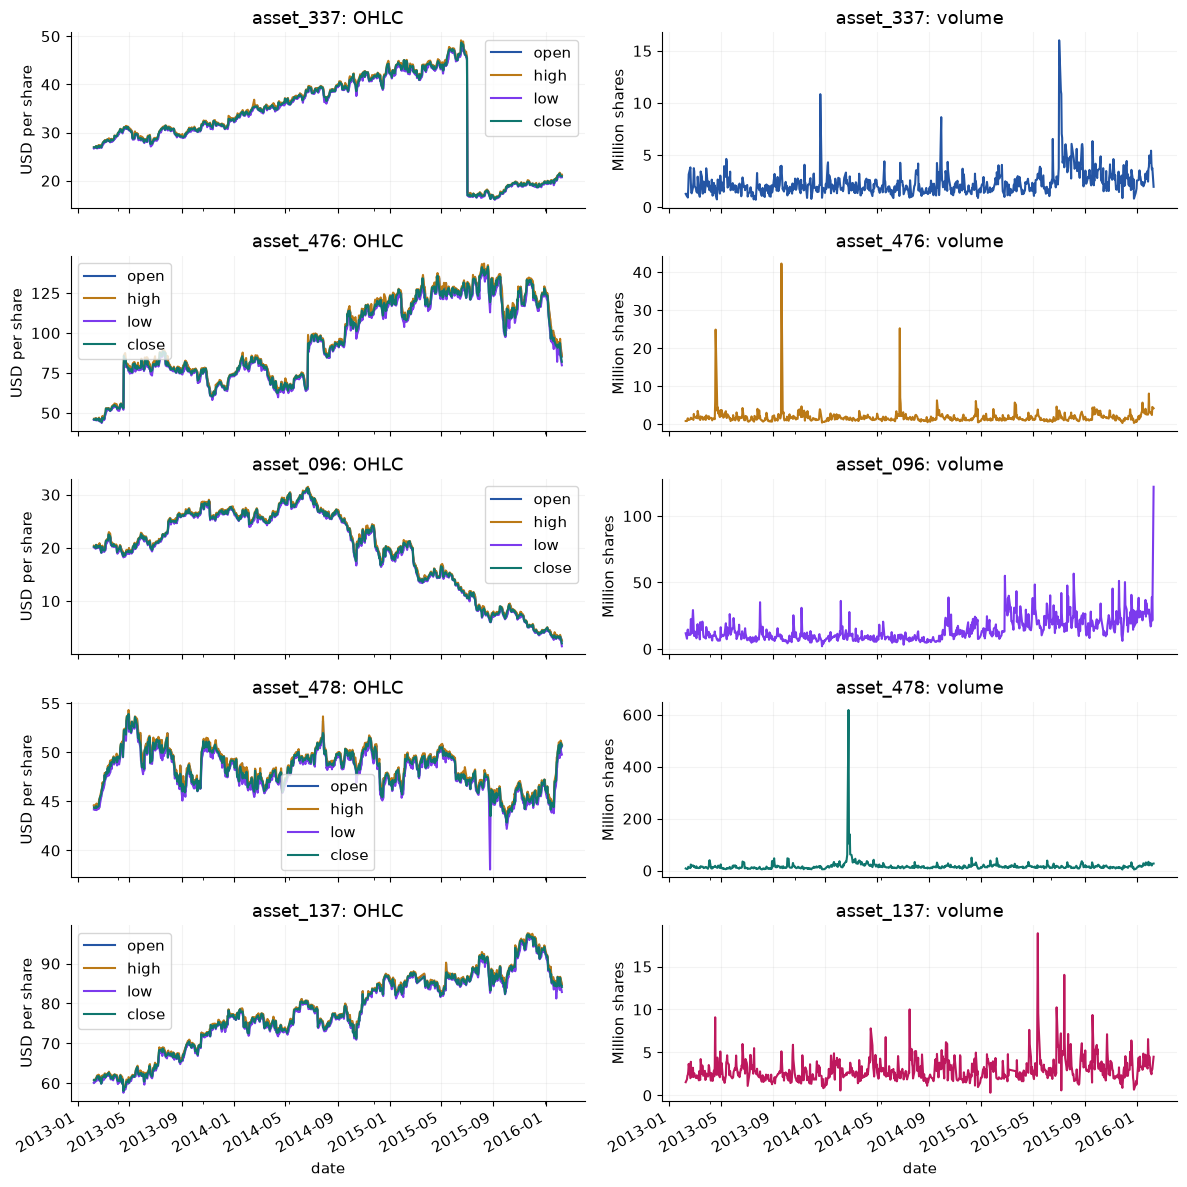

In [14]:
fig, axes = plt.subplots(len(stocks), 2, figsize=(12, 12), sharex=True)
for row, stock in enumerate(stocks):
    history = eda.loc[eda['Name'] == stock].set_index('date')
    history[price_cols].plot(ax=axes[row, 0], color=colors[:4], title=f'{stock}: OHLC')
    axes[row, 0].set_ylabel('USD per share')
    volume_millions = history['volume'] / 1e6
    volume_millions.plot(ax=axes[row, 1], color=colors[row], title=f'{stock}: volume')
    axes[row, 1].set_ylabel('Million shares')
fig.tight_layout()
plt.show()

Prices show trends and sharp moves; volume has occasional spikes. At this scale, the four OHLC lines often overlap.

### Return histories

Daily close-to-close returns, with separate vertical scales and missing sessions left as gaps.

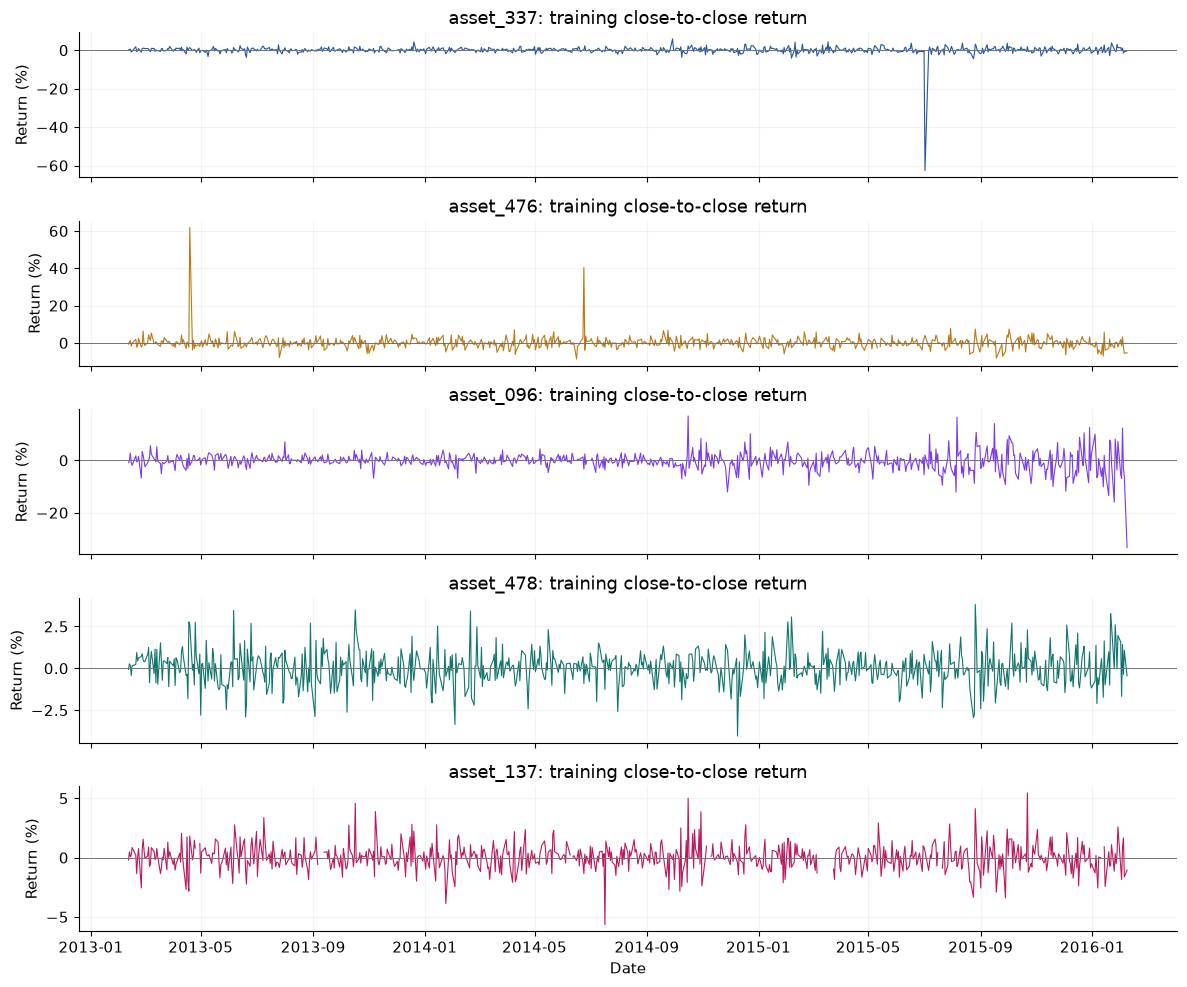

In [15]:
fig, axes = plt.subplots(len(stocks), 1, figsize=(12, 10), sharex=True)
for ax, name, color in zip(axes, stocks, colors):
    ax.plot(eda_returns.index, 100 * eda_returns[name], color=color, linewidth=.8)
    ax.axhline(0, color='#71717a', linewidth=.7)
    ax.set(title=f'{name}: training close-to-close return', ylabel='Return (%)')
axes[-1].set_xlabel('Date')
fig.tight_layout()
plt.show()

Return sizes vary over time and across stocks. asset_337 has a particularly large negative jump, which needs source review.

### Inspect a large move

Zoom into asset_337 around July 2015. Verify source adjustments before correcting the discontinuity.

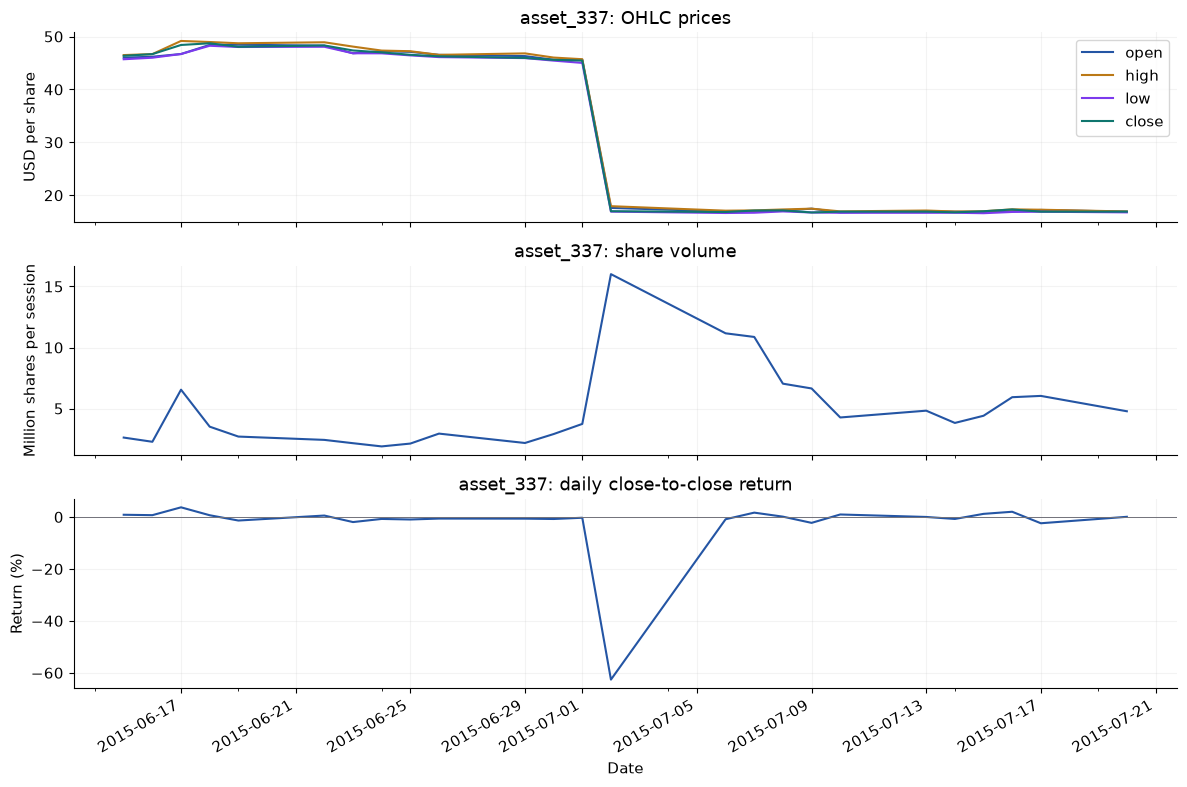

In [16]:
stock = 'asset_337'
start_date = '2015-06-15'
end_date = '2015-07-20'

history = eda.loc[eda['Name'] == stock].set_index('date').reindex(eda_close.index)
history = history.loc[start_date:end_date]
assert not history.empty, 'Choose a selected stock and a date range within the training period.'

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
history[price_cols].plot(ax=axes[0], color=colors[:4], title=f'{stock}: OHLC prices')
axes[0].set_ylabel('USD per share')
history['volume'].div(1e6).plot(ax=axes[1], color=colors[0], title=f'{stock}: share volume')
axes[1].set_ylabel('Million shares per session')
eda_returns.loc[start_date:end_date, stock].mul(100).plot(
    ax=axes[2], color=colors[0], title=f'{stock}: daily close-to-close return')
axes[2].axhline(0, color='#71717a', linewidth=.7)
axes[2].set_ylabel('Return (%)')
axes[2].set_xlabel('Date')
fig.tight_layout()
plt.show()

asset_337's closing price drops sharply in early July 2015. The discontinuity is retained pending adjustment checks.

### Return statistics

Compare sample sizes, tails, skewness and excess kurtosis.

In [17]:
return_stats = eda_returns.describe(percentiles=[.01, .05, .50, .95, .99]).T
return_stats['skew'] = eda_returns.skew()
return_stats['excess_kurtosis'] = eda_returns.kurt()
display(return_stats.round(4))

,count,mean,std,min,1%,5%,50%,95%,99%,max,skew,excess_kurtosis
Name,,,,,,,,,,,,
asset_096,752.0,-0.0023,0.0355,-0.3333,-0.0977,-0.0600,-0.0015,0.0459,0.1007,0.1699,-0.8853,12.9062
asset_137,729.0,0.0005,0.0112,-0.0564,-0.0269,-0.0168,0.0005,0.0176,0.0290,0.0545,0.2410,2.8814
asset_337,754.0,0.0002,0.0259,-0.6262,-0.0306,-0.0187,0.0007,0.0204,0.0340,0.0586,-18.8572,457.2497
asset_476,752.0,0.0013,0.0361,-0.0867,-0.0607,-0.0395,0.0001,0.0414,0.0644,0.6191,8.4800,133.3800
asset_478,754.0,0.0002,0.0103,-0.0405,-0.0260,-0.0159,0.0005,0.0166,0.0275,0.0382,0.1294,1.2186


### Indexed closing prices

Start each series at 100 on the first training date. These are supplied prices, without verified dividend or corporate-action adjustments.

,training_price_change_pct
Name,
asset_337,-22.33
asset_476,78.26
asset_096,-89.92
asset_478,14.41
asset_137,38.37


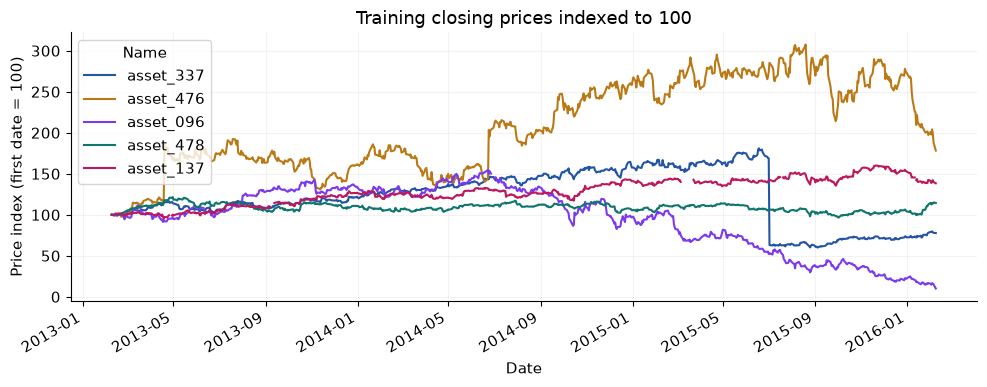

In [18]:
normalized = 100 * eda_close[stocks] / eda_close[stocks].iloc[0]
price_changes = (normalized.iloc[-1] - 100).to_frame('training_price_change_pct')
display(price_changes.round(2))

normalized.plot(figsize=(10, 4), color=colors,
                title='Training closing prices indexed to 100',
                ylabel='Price index (first date = 100)', xlabel='Date')
plt.tight_layout()
plt.show()

asset_476 rises about **78%** and asset_096 falls about **90%** over training. Indexing makes proportional changes comparable across stocks.

### Return distributions

Keep all returns; use a log count axis to show sparse tails. Horizontal scales differ.

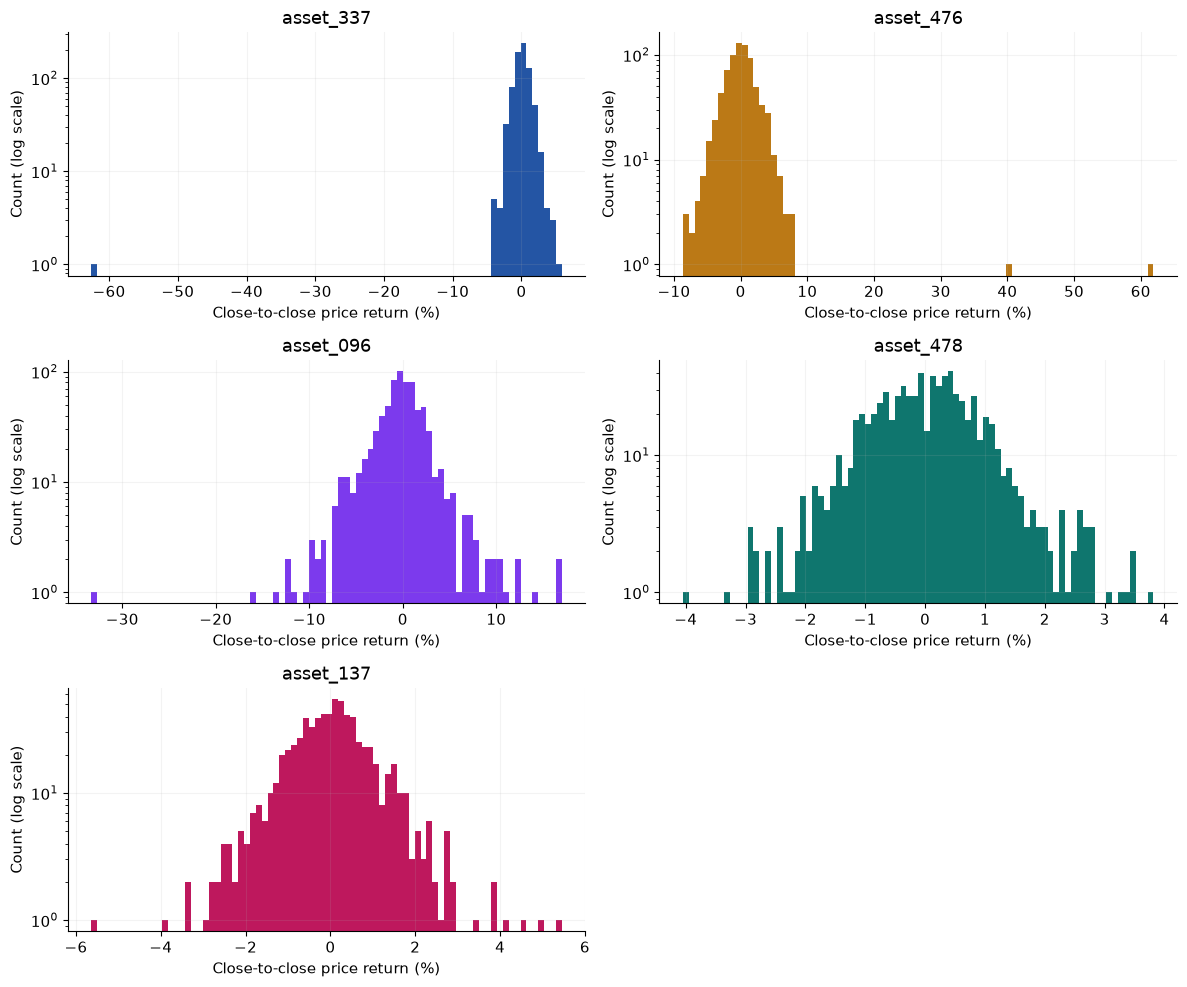

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, stock, color in zip(axes.flat, stocks, colors):
    ax.hist(100 * eda_returns[stock].dropna(), bins=80, log=True, color=color)
    ax.set(title=stock, xlabel='Close-to-close price return (%)', ylabel='Count (log scale)')
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()

Most daily returns cluster near zero, with sparse large moves in both directions. The tails and skewness differ across stocks.

### Rolling volatility

20-session sample standard deviation of daily returns, in percent; not annualized.

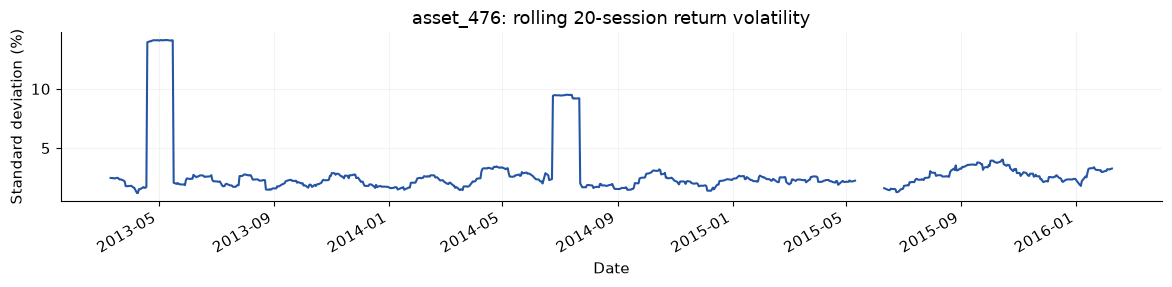

In [20]:
(100 * candidate_features['volatility20'][focus_stock]).plot(
    figsize=(12, 3), color=colors[0],
    title=f'{focus_stock}: rolling 20-session return volatility',
    ylabel='Standard deviation (%)', xlabel='Date')
plt.tight_layout()
plt.show()

asset_476 alternates between quieter and more volatile periods. This motivates checking dependence in return magnitude.

### Cross-stock correlations

Use matching-date returns, with at least 100 pairs per correlation.

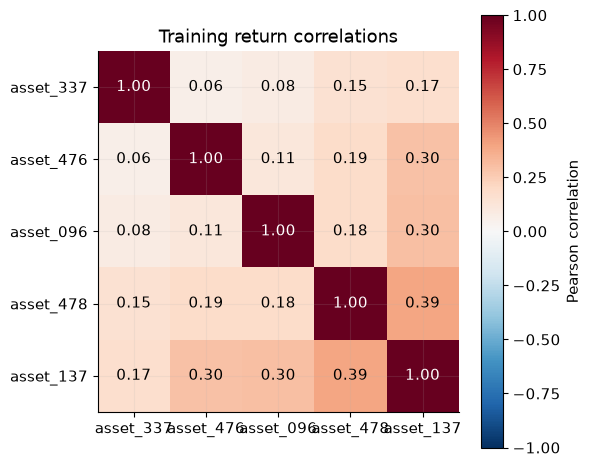

In [21]:
corr = eda_returns[stocks].corr(min_periods=100)
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(stocks)), stocks)
ax.set_yticks(range(len(stocks)), stocks)
for (row, column), value in np.ndenumerate(corr.to_numpy()):
    text_color = 'white' if abs(value) > .6 else 'black'
    ax.text(column, row, f'{value:.2f}', ha='center', va='center', color=text_color)
ax.set_title('Training return correlations')
fig.colorbar(image, ax=ax, label='Pearson correlation')
fig.tight_layout()
plt.show()

Same-day return correlations vary across stock pairs. They motivate testing a cross-stock feature, but do not establish next-session predictability.

### Average share volume

Mean shares per observed training session.

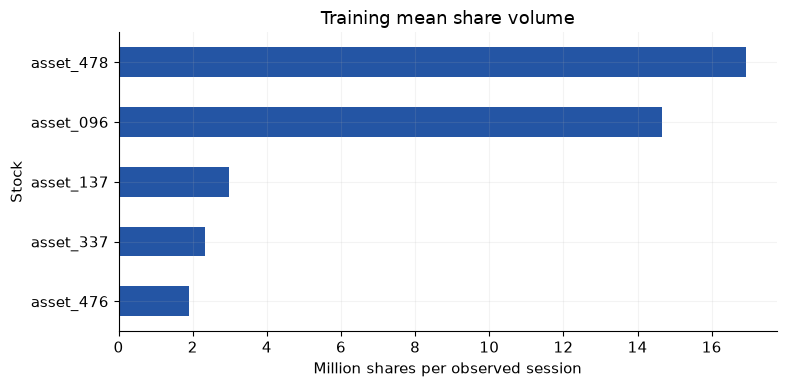

In [22]:
mean_volume = eda.groupby('Name')['volume'].mean() / 1e6
mean_volume.sort_values().plot.barh(
    figsize=(8, 4), color=colors[0], title='Training mean share volume',
    xlabel='Million shares per observed session', ylabel='Stock'
)
plt.tight_layout()
plt.show()

asset_478 and asset_096 have the highest average share volumes in this sample. Share volume alone is an incomplete liquidity measure.

### Volume and return magnitude

For asset_476, compare today's relative volume with today's absolute return:

$$RV_t=\frac{V_t}{\frac{1}{20}\sum_{j=0}^{19}V_{t-j}},\qquad 100|r_t|.$$

The volume average includes today. Each dot is one complete training session.

Same-day Pearson correlation: 0.58


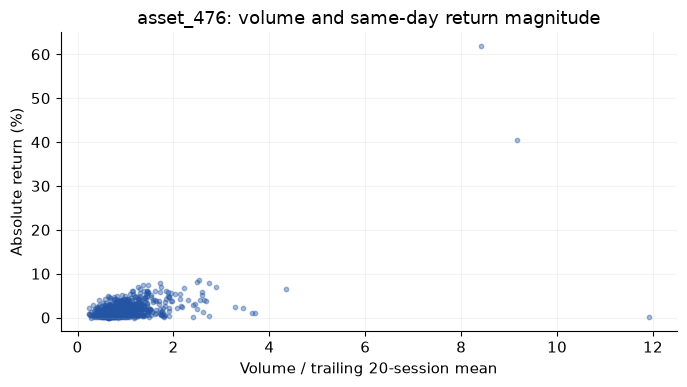

In [23]:
relative_volume = candidate_features['relative_volume'][focus_stock]
absolute_return = eda_returns[focus_stock].abs()
print('Same-day Pearson correlation:', round(relative_volume.corr(absolute_return), 2))

plt.figure(figsize=(7, 4))
plt.scatter(relative_volume, 100 * absolute_return, s=10, alpha=.4, color=colors[0])
plt.xlabel('Volume / trailing 20-session mean')
plt.ylabel('Absolute return (%)')
plt.title(f'{focus_stock}: volume and same-day return magnitude')
plt.tight_layout()
plt.show()

Higher relative volume tends to accompany larger asset_476 moves (**Pearson correlation 0.58**), with influential extremes. This is same-day association.

### Today's features versus tomorrow's return

Report pair counts, Pearson correlations and Spearman rank correlations for all five stocks; plot asset_476.

In [24]:
relationships = []
for name in stocks:
    for feature, values in candidate_features.items():
        pairs = pd.DataFrame({'feature': values[name], 'target': future_return[name]}).dropna()
        relationships.append({
            'stock': name, 'feature': feature, 'pairs': len(pairs),
            'pearson': pairs['feature'].corr(pairs['target']),
            'spearman': pairs['feature'].corr(pairs['target'], method='spearman')
        })
future_relationships = pd.DataFrame(relationships)
display(future_relationships.set_index(['stock', 'feature']).round(4))

pairs  pearson  spearman
stock     feature                                  
asset_337 current_return     753   0.0099   -0.0250
          relative_volume    735  -0.0369    0.0187
          volatility20       734   0.0071    0.0158
          price_range        754  -0.0037   -0.0222
asset_476 current_return     750  -0.0342   -0.0119
          relative_volume    714   0.0141   -0.0834
          volatility20       712  -0.0269   -0.0326
          price_range        752  -0.0535   -0.0706
asset_096 current_return     750   0.0245    0.0327
          relative_volume    714  -0.0185   -0.0231
          volatility20       712  -0.0858   -0.0812
          price_range        752  -0.0221   -0.0563
asset_478 current_return     753   0.0069   -0.0367
          relative_volume    735   0.0013    0.0132
          volatility20       734   0.0562    0.0386
          price_range        754  -0.0316    0.0140
asset_137 current_return     721  -0.0892   -0.0949
          relative_volume    579   0.0520    0.0549
          volatility20       572   0.0752    0.0622
          price_range        729   0.0621    0.0857

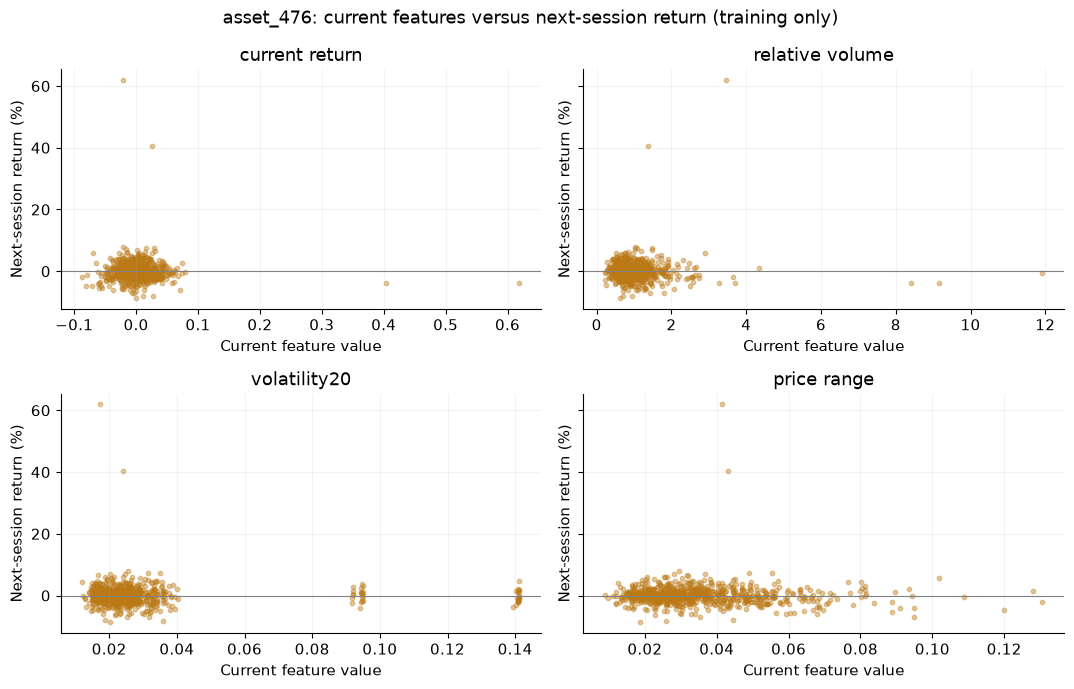

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, (feature, values) in zip(axes.flat, candidate_features.items()):
    pairs = pd.DataFrame({'feature': values[focus_stock],
                          'target': future_return[focus_stock]}).dropna()
    ax.scatter(pairs['feature'], 100 * pairs['target'], s=10, alpha=.4, color=colors[1])
    ax.axhline(0, color='grey', linewidth=.8)
    ax.set(title=feature.replace('_', ' '), xlabel='Current feature value',
           ylabel='Next-session return (%)')
fig.suptitle(f'{focus_stock}: current features versus next-session return (training only)')
fig.tight_layout()
plt.show()

asset_476's feature-versus-target clouds show no clear relationship. The training correlations alone do not establish predictive value.

### Stability over time

Compare moving averages, rolling means and standard deviations, and return statistics by year. Training years 2013 and 2016 are partial.

date                2013     2014     2015    2016
Name                                              
asset_096 count  225.000  250.000  252.000  25.000
          mean     0.146   -0.081   -0.491  -2.607
          std      1.778    2.637    4.270   9.681
asset_137 count  219.000  248.000  239.000  23.000
          mean     0.099    0.049    0.033  -0.325
          std      1.068    1.139    1.133   1.278
asset_337 count  225.000  252.000  252.000  25.000
          mean     0.094    0.107   -0.156   0.290
          std      1.020    1.126    4.193   1.615
asset_476 count  225.000  252.000  250.000  25.000
          mean     0.297    0.239    0.051  -1.651
          std      4.649    3.451    2.570   3.114
asset_478 count  225.000  252.000  252.000  25.000
          mean     0.051   -0.015    0.000   0.384
          std      1.090    0.934    1.001   1.482

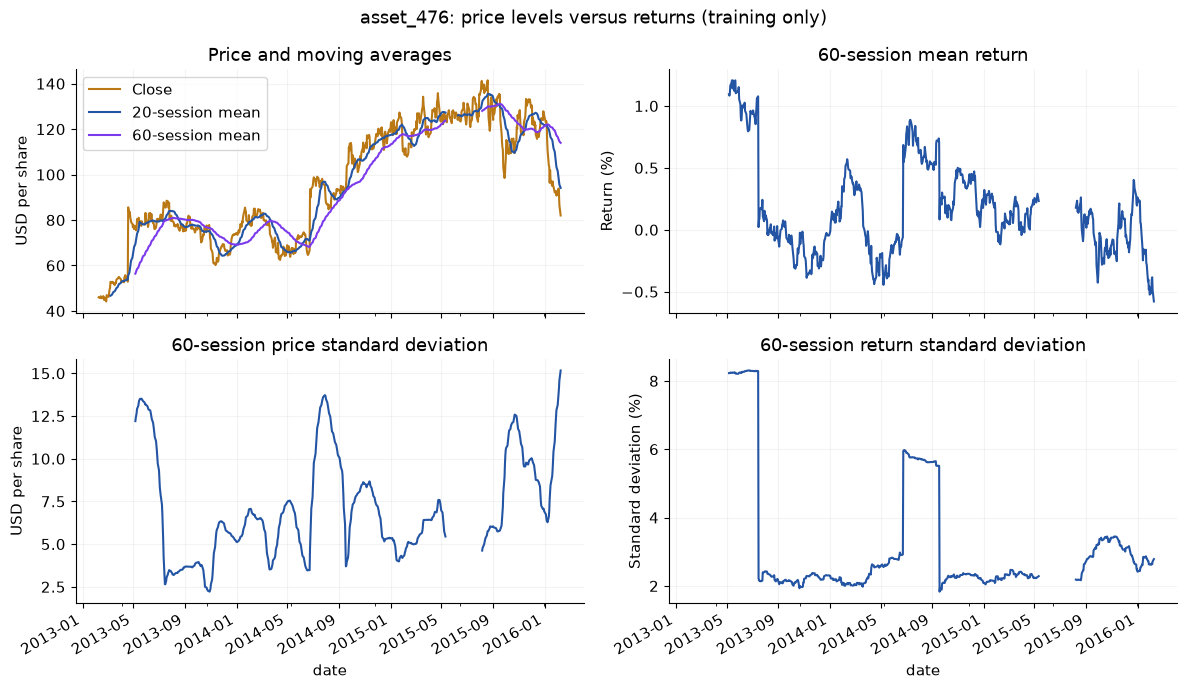

In [26]:
yearly_return_stats = (100 * eda_returns).groupby(eda_returns.index.year).agg(['count', 'mean', 'std'])
display(yearly_return_stats.T.round(3))

price = eda_close[focus_stock]
daily_return_pct = 100 * eda_returns[focus_stock]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)

price.plot(ax=axes[0, 0], color=colors[1], label='Close')
price.rolling(20).mean().plot(ax=axes[0, 0], color=colors[0], label='20-session mean')
price.rolling(60).mean().plot(ax=axes[0, 0], color=colors[2], label='60-session mean')
axes[0, 0].set(title='Price and moving averages', ylabel='USD per share')
axes[0, 0].legend()
price.rolling(60).std().plot(ax=axes[1, 0], color=colors[0])
axes[1, 0].set(title='60-session price standard deviation', ylabel='USD per share')
daily_return_pct.rolling(60).mean().plot(ax=axes[0, 1], color=colors[0])
axes[0, 1].set(title='60-session mean return', ylabel='Return (%)')
daily_return_pct.rolling(60).std().plot(ax=axes[1, 1], color=colors[0])
axes[1, 1].set(title='60-session return standard deviation', ylabel='Standard deviation (%)')
fig.suptitle(f'{focus_stock}: price levels versus returns (training only)')
fig.tight_layout()
plt.show()

asset_476 has a changing price level and return variability. The 60-session mean return stays small relative to daily fluctuations.

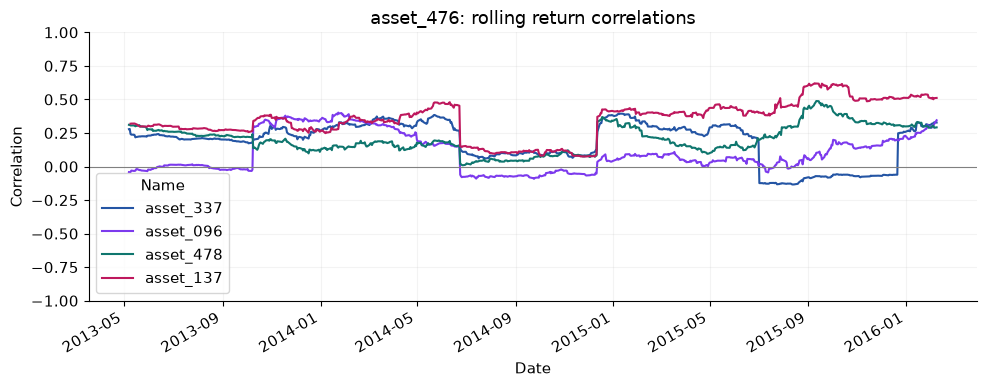

In [27]:
other_stocks = stocks.copy()
other_stocks.remove(focus_stock)
rolling_correlations = eda_returns[other_stocks].rolling(120, min_periods=60).corr(
    eda_returns[focus_stock]
)
correlation_colors = []
for stock in other_stocks:
    correlation_colors.append(colors[stocks.index(stock)])
rolling_correlations.plot(
    figsize=(10, 4), ylim=(-1, 1), color=correlation_colors,
    title=f'{focus_stock}: rolling return correlations', xlabel='Date', ylabel='Correlation'
)
plt.axhline(0, color='grey', linewidth=.8)
plt.tight_layout()
plt.show()

Rolling correlations between asset_476 and the other stocks change through training. Each window uses 120 sessions and at least 60 matching pairs.

### Serial dependence

Use each stock's longest uninterrupted training-return stretch. Plot lags **1–20**; joint tests and lag contributions use **1–10**. These are fixed exploratory choices.

In [28]:
def longest_complete_block(series):
    present = series.notna()
    runs = present.ne(present.shift()).cumsum()
    longest_run = series[present].groupby(runs).size().idxmax()
    return series[present & runs.eq(longest_run)]

diagnostic_lags = 10
plot_lags = 20
training_blocks = {}
for stock in stocks:
    training_blocks[stock] = longest_complete_block(eda_returns[stock])

#### ACF and PACF

ACF measures correlation with a lag; PACF accounts for intervening lags. Compare returns, absolute returns and squared deviations $(r_t-\bar r)^2$.

Use Bonferroni bands across $5\times4\times20=400$ coefficients: $\alpha=0.05/400$. ACF uses Bartlett standard errors; PACF uses $1/\sqrt n$. The bands aim for 95% simultaneous coverage under these approximations; heavy tails can affect them.

[ACF](https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_acf.html) · [PACF](https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_pacf.html)

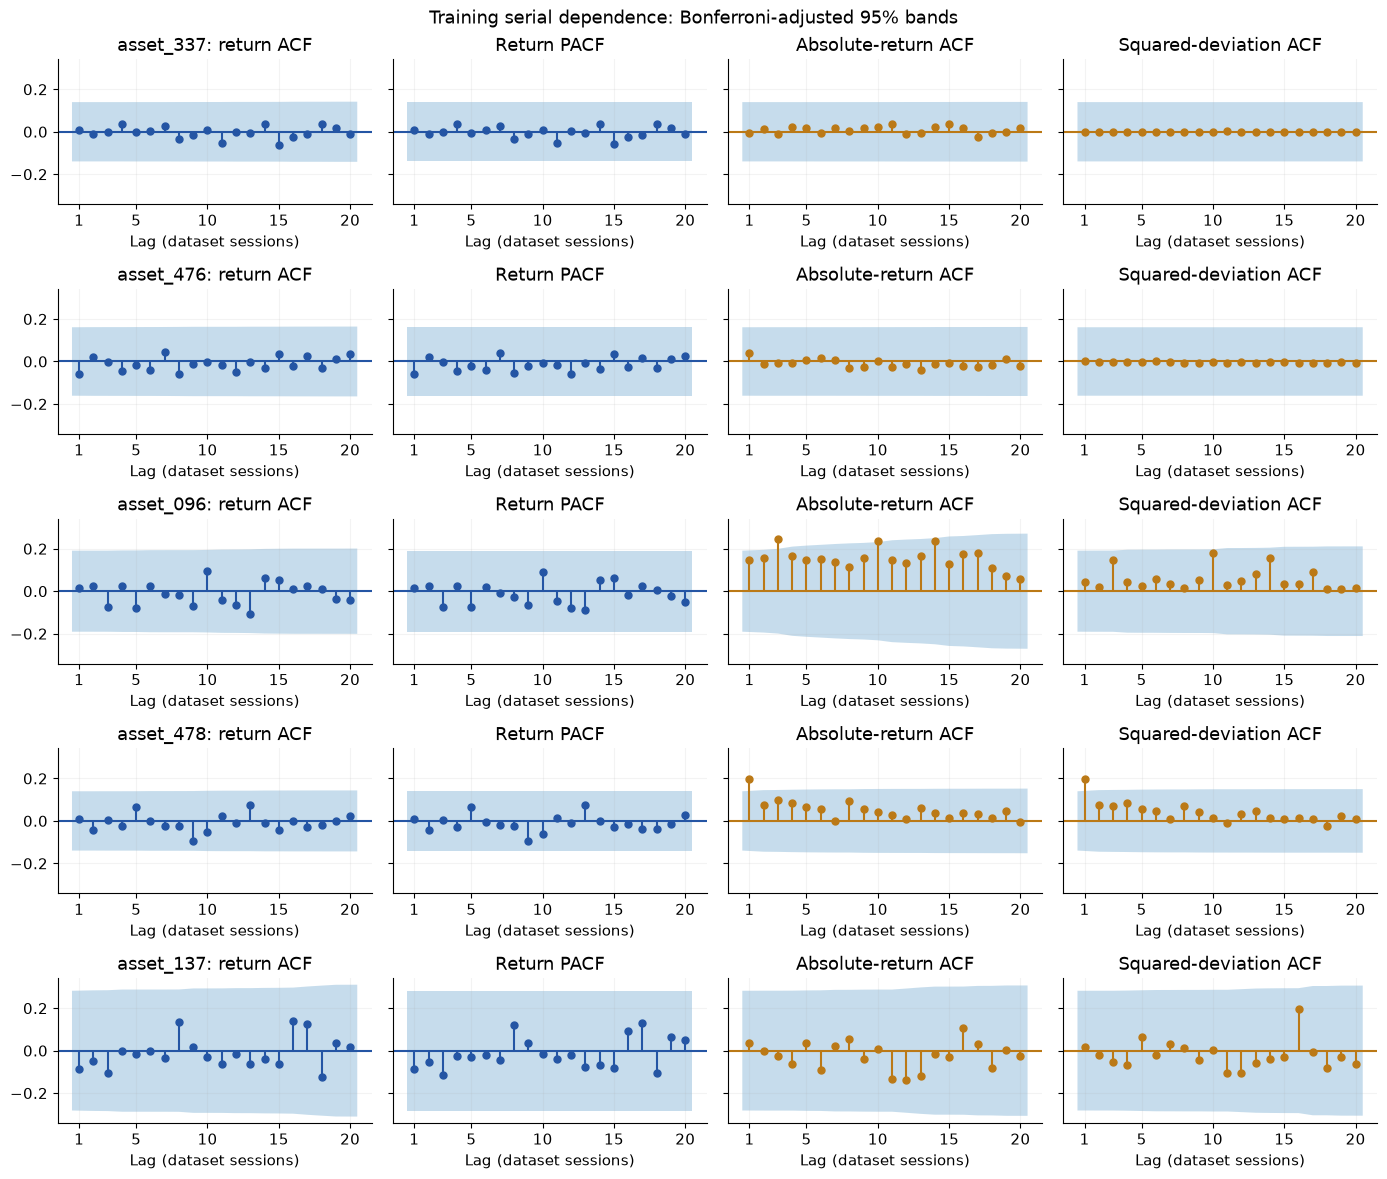

In [29]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

n_comparisons = len(stocks) * 4 * plot_lags
plot_alpha = 0.05 / n_comparisons

fig, axes = plt.subplots(len(stocks), 4, figsize=(14, 12), sharey=True)
for i, name in enumerate(stocks):
    block = training_blocks[name]
    squared = (block - block.mean()) ** 2
    plot_acf(block, lags=plot_lags, alpha=plot_alpha, zero=False, ax=axes[i, 0],
             title=f'{name}: return ACF', color=colors[0],
             vlines_kwargs={'colors': colors[0]})
    plot_pacf(block, lags=plot_lags, alpha=plot_alpha, zero=False, method='ywm', ax=axes[i, 1],
              title='Return PACF', color=colors[0],
              vlines_kwargs={'colors': colors[0]})
    plot_acf(block.abs(), lags=plot_lags, alpha=plot_alpha, zero=False, ax=axes[i, 2],
             title='Absolute-return ACF', color=colors[1],
             vlines_kwargs={'colors': colors[1]})
    plot_acf(squared, lags=plot_lags, alpha=plot_alpha, zero=False, ax=axes[i, 3],
             title='Squared-deviation ACF', color=colors[1],
             vlines_kwargs={'colors': colors[1]})

for ax in axes.flat:
    ax.autoscale(axis='y')
    ax.set(xlabel='Lag (dataset sessions)', xticks=[1, 5, 10, 15, 20])
fig.suptitle('Training serial dependence: Bonferroni-adjusted 95% bands')
fig.tight_layout()
plt.show()

Return ACF/PACF show little clear structure; asset_096 and asset_478 have more visible dependence in return magnitude. Wide bands account for the 400 plotted comparisons.

#### Joint tests

Ljung–Box tests whether autocorrelations at lags 1–10 are jointly zero, separately for returns, absolute returns and squared deviations.

For ARCH LM, regress squared deviations on their ten lags:

$$z_t=(r_t-\bar r)^2,\qquad z_t=a+\sum_{j=1}^{10}b_jz_{t-j}+u_t,\qquad LM=nR^2.$$

Here $n$ counts regression rows after lagging. Adjust p-values with Holm across all **20 tests**; compare with 0.05.

[Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html) · [ARCH LM](https://www.statsmodels.org/stable/_modules/statsmodels/stats/diagnostic.html#het_arch)

In [30]:
from sklearn.linear_model import LinearRegression
from scipy.stats import chi2
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests

test_rows = []
arch_rows = []
arch_regressions = {}
for name, block in training_blocks.items():
    squared = (block - block.mean()) ** 2
    for test, values in [('LB return', block), ('LB absolute', block.abs()),
                          ('LB squared', squared)]:
        result = acorr_ljungbox(values, lags=[diagnostic_lags], return_df=True).iloc[0]
        test_rows.append({'stock': name, 'test': test,
                          'statistic': result['lb_stat'], 'p_raw': result['lb_pvalue']})

    # The ARCH regression is also reused for the lag-contribution analysis.
    lagged = pd.DataFrame(index=block.index)
    for lag in range(1, diagnostic_lags + 1):
        lagged[f'lag_{lag}'] = squared.shift(lag)
    data = lagged.assign(target=squared).dropna()
    X = data.drop(columns='target')
    y = data['target']
    model = LinearRegression().fit(X, y)
    arch_regressions[name] = (X, y, model)
    r_squared = model.score(X, y)
    lm = len(data) * r_squared
    test_rows.append({'stock': name, 'test': 'ARCH LM',
                      'statistic': lm, 'p_raw': chi2.sf(lm, df=diagnostic_lags)})
    arch_rows.append({'stock': name, 'n': len(data), 'R_squared': r_squared})

autocorrelation_tests = pd.DataFrame(test_rows)
autocorrelation_tests['p_holm'] = multipletests(
    autocorrelation_tests['p_raw'], method='holm')[1]
arch_tests = pd.DataFrame(arch_rows).set_index('stock')
arch_tests['p_holm'] = (autocorrelation_tests[autocorrelation_tests['test'] == 'ARCH LM']
                       .set_index('stock')['p_holm'])

test_summary = autocorrelation_tests.pivot(index='stock', columns='test', values='p_holm')
test_summary['n_train'] = pd.Series(training_blocks).map(len)
test_summary['ARCH_R2'] = arch_tests['R_squared']
display(test_summary.reindex(stocks)[['n_train', 'ARCH_R2', 'LB return',
                                     'LB absolute', 'LB squared', 'ARCH LM']])

test,n_train,ARCH_R2,LB return,LB absolute,LB squared,ARCH LM
stock,,,,,,
asset_337,754,0.000020,1.0,1.000000e+00,1.000000,1.000000e+00
asset_476,566,0.000157,1.0,1.000000e+00,1.000000,1.000000e+00
asset_096,404,0.161254,1.0,1.165381e-19,0.028515,1.467481e-08
asset_478,754,0.051325,1.0,2.160712e-08,0.000001,5.636564e-04
asset_137,185,0.016696,1.0,1.000000e+00,1.000000,1.000000e+00


After Holm adjustment, no stock shows significant return autocorrelation. **asset_096 and asset_478** show dependence in return magnitude and significant ARCH effects.

The tests do not establish an AR order. Heavy tails, isolated jumps and changing volatility affect their interpretation.

#### Contribution of each squared-return lag

Remove one ARCH lag and refit on the same rows:

$$\Delta R_j^2=R^2_{\text{all lags}}-R^2_{\text{without }j}.$$

Report $100\Delta R_j^2$ in percentage points. Plot stocks with significant ARCH joint tests; these are training contributions, not individual-lag tests.

In [31]:
lag_results = []
for stock, (X, y, model) in arch_regressions.items():
    full_r2 = model.score(X, y)
    for lag in range(1, diagnostic_lags + 1):
        reduced_X = X.drop(columns=f'lag_{lag}')
        reduced_model = LinearRegression().fit(reduced_X, y)
        lag_results.append({
            'stock': stock, 'lag': lag, 'coefficient': model.coef_[lag - 1],
            'R2_drop_pp': 100 * (full_r2 - reduced_model.score(reduced_X, y))
        })

arch_lag_scores = pd.DataFrame(lag_results)
best_rows = arch_lag_scores.groupby('stock')['R2_drop_pp'].idxmax()
best_arch_lags = arch_lag_scores.loc[best_rows].set_index('stock').reindex(stocks)
display(best_arch_lags.round(4))

,lag,coefficient,R2_drop_pp
stock,,,
asset_337,3,-0.0020,0.0004
asset_476,8,-0.0057,0.0033
asset_096,10,0.5291,8.3077
asset_478,1,0.1835,3.1917
asset_137,4,-0.0683,0.4582


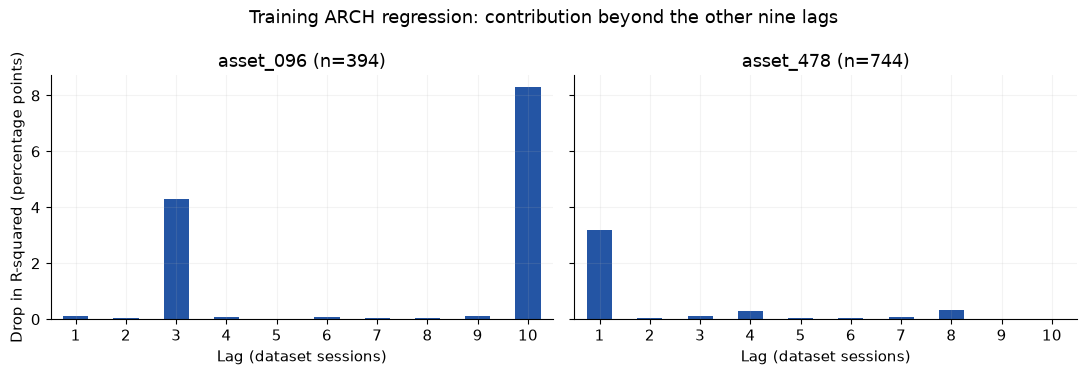

In [32]:
significant_stocks = arch_tests.index[arch_tests['p_holm'] < 0.05]
lag_contributions = arch_lag_scores.pivot(index='lag', columns='stock', values='R2_drop_pp')
axes = lag_contributions[significant_stocks].plot.bar(
    subplots=True, layout=(1, len(significant_stocks)), sharey=True,
    figsize=(11, 3.8), color=colors[0], legend=False, rot=0)
for ax, name in zip(axes.flat, significant_stocks):
    ax.set(title=f'{name} (n={arch_tests.loc[name, "n"]})',
           xlabel='Lag (dataset sessions)', ylabel='Drop in R-squared (percentage points)',
           ylim=(0, None))
plt.suptitle('Training ARCH regression: contribution beyond the other nine lags')
plt.tight_layout()
plt.show()

Lag **10** contributes most for asset_096 (**8.31 pp** of $R^2$); lag **1** contributes most for asset_478 (**3.19 pp**). Contributions overlap and do not select a GARCH order.

#### Longer lags

Check approximate monthly (21), quarterly (63) and annual (252) session lags. Shift on the full training grid before dropping missing pairs; display pair counts.

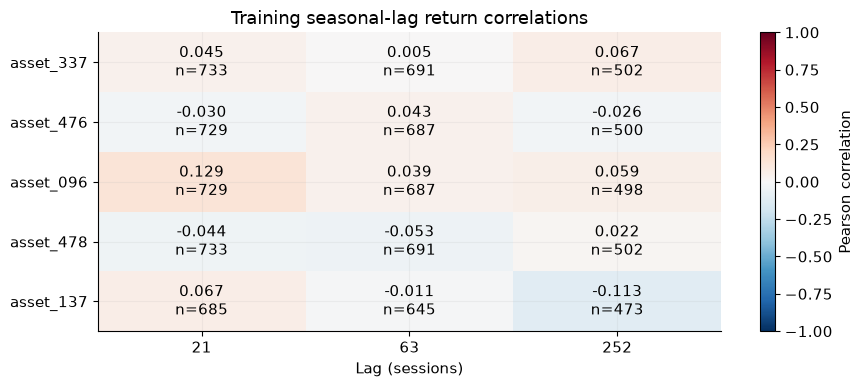

In [33]:
seasonal_lags = [21, 63, 252]
seasonal_corr = pd.DataFrame(index=stocks, columns=seasonal_lags, dtype=float)
seasonal_pairs = pd.DataFrame(0, index=stocks, columns=seasonal_lags)

current_returns = eda_returns[stocks]
for lag in seasonal_lags:
    past_returns = current_returns.shift(lag)
    seasonal_corr[lag] = current_returns.corrwith(past_returns)
    seasonal_pairs[lag] = (current_returns.notna() & past_returns.notna()).sum()

fig, ax = plt.subplots(figsize=(9, 4))
image = ax.imshow(seasonal_corr, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(seasonal_lags)), seasonal_lags)
ax.set_yticks(range(len(stocks)), stocks)
ax.set(xlabel='Lag (sessions)', title='Training seasonal-lag return correlations')
for (row, column), value in np.ndenumerate(seasonal_corr.to_numpy()):
    count = seasonal_pairs.iloc[row, column]
    ax.text(column, row, f'{value:.3f}\nn={count}', ha='center', va='center')
fig.colorbar(image, ax=ax, label='Pearson correlation')
fig.tight_layout()
plt.show()

The largest absolute correlation is about **0.13**, for asset_096 at 21 sessions. These limited training pairs do not establish seasonality.

#### Weekdays

Compare training means and medians by the weekday a return ends. Labels show sample sizes; these are descriptive summaries.

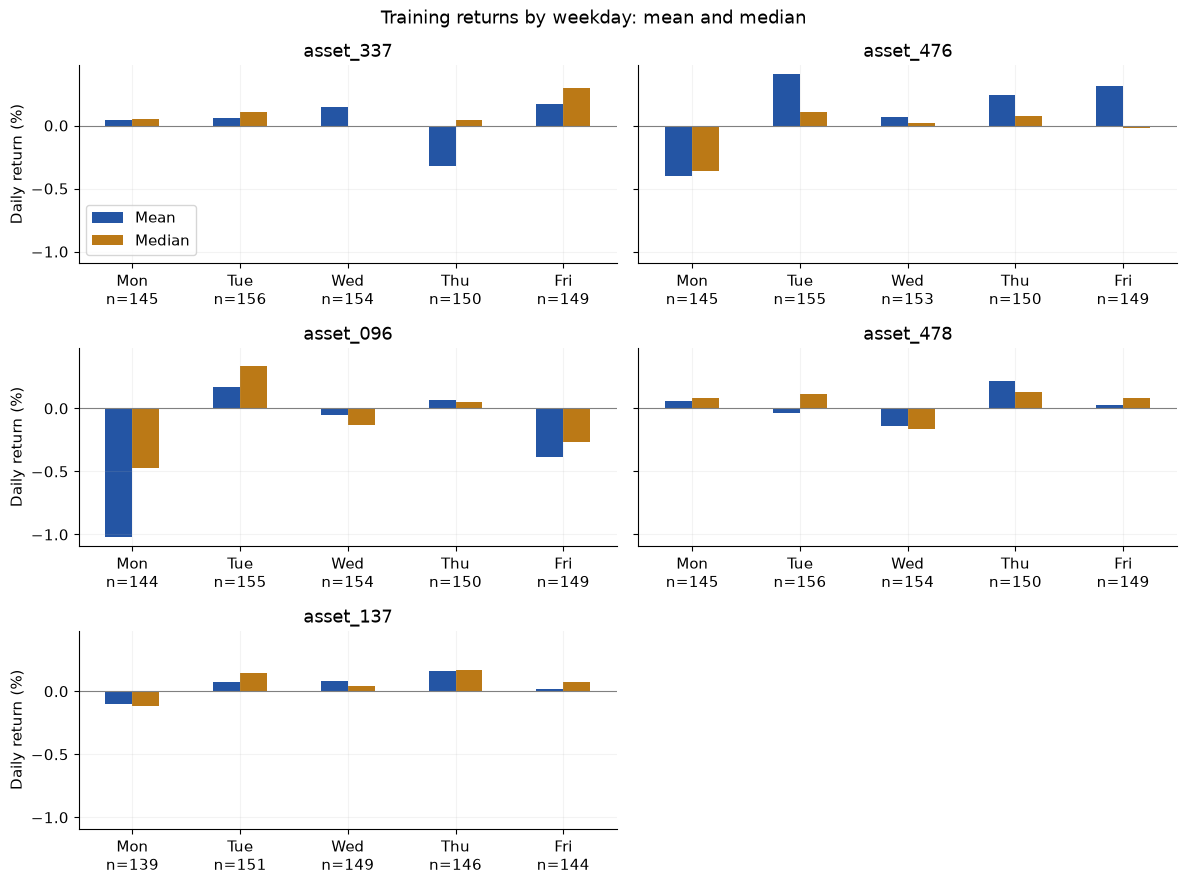

In [34]:
weekday_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri']
weekday_stats = eda_returns.groupby(eda_returns.index.dayofweek).agg(['count', 'mean', 'median'])

fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharey=True)
for i, name in enumerate(stocks):
    ax = axes.flat[i]
    stats = weekday_stats[name].reindex(range(5))
    (100 * stats[['mean', 'median']]).rename(
        columns={'mean': 'Mean', 'median': 'Median'}
    ).plot.bar(ax=ax, color=colors[:2], legend=(i == 0))
    ax.set_xticklabels([f'{day}\nn={int(stats.loc[j, "count"])}'
                        for j, day in enumerate(weekday_labels)], rotation=0)
    ax.axhline(0, color='grey', linewidth=.8)
    ax.set(title=name, xlabel='', ylabel='Daily return (%)')
axes.flat[-1].axis('off')
fig.suptitle('Training returns by weekday: mean and median')
fig.tight_layout()
plt.show()

asset_096 Mondays are negative by both mean and median; asset_337 Thursdays have a negative mean but positive median. These patterns need confirmation in later periods.

## 4. Features

Use information available after session $t$ closes. The eleven inputs are fractions or ratios; rolling windows include today.

Let $\bar r_{k,t}$ and $s_{k,t}$ be the mean and sample standard deviation of the latest $k$ returns; $\bar V_{20,t}$ is the latest 20-session mean volume.

| Feature | Formula at $t$ |
|---|---|
| `return_t` | $r_t$ |
| `return_lag1` | $r_{t-1}$ |
| `return_lag2` | $r_{t-2}$ |
| `mean_return5` | $\bar r_{5,t}$ |
| `volatility20` | $s_{20,t}$ |
| `relative_volume20` | $\frac{V_t}{\bar V_{20,t}}$ |
| `price_range` | $\frac{H_t-L_t}{C_t}$ |
| `intraday_return` | $\frac{C_t}{O_t}-1$ |
| `close_position` | $\frac{C_t-L_t}{H_t-L_t}$ |
| `cumulative_return20` | $\frac{C_t}{C_{t-20}}-1$ |
| `volatility_ratio` | $\frac{s_{5,t}}{s_{20,t}}$ |

The target is $r_{t+1}$. Windows and features are fixed candidates, not established signals.

### Build each stock separately

Create lags and windows on the shared date grid, then drop incomplete feature-target rows. Zero denominators remain missing.

**Additional candidate:** `other_return_t` is today's mean return of the other four stocks:

$$m_{i,t}=\frac{1}{4}\sum_{j\ne i}r_{j,t}.$$

Require all four returns. Test this feature separately on matched rows.

In [35]:
feature_cols = [
    'return_t', 'return_lag1', 'return_lag2', 'mean_return5', 'volatility20',
    'relative_volume20', 'price_range', 'intraday_return', 'close_position',
    'cumulative_return20', 'volatility_ratio'
]
ar_features = ['return_t', 'return_lag1', 'return_lag2']
next_date = pd.Series(dates, index=dates).shift(-1)

feature_frames = []
for stock in stocks:
    history = df.loc[df['Name'] == stock].set_index('date').reindex(dates)
    stock_returns = returns[stock]
    daily_range = history['high'] - history['low']
    mean_volume20 = history['volume'].rolling(20).mean().replace(0, np.nan)

    features = pd.DataFrame(index=dates)
    features['Name'] = stock
    features['return_t'] = stock_returns
    features['return_lag1'] = stock_returns.shift(1)
    features['return_lag2'] = stock_returns.shift(2)
    features['mean_return5'] = stock_returns.rolling(5).mean()
    features['volatility20'] = stock_returns.rolling(20).std()
    features['relative_volume20'] = history['volume'] / mean_volume20
    features['price_range'] = daily_range / history['close']
    features['intraday_return'] = history['close'] / history['open'] - 1
    features['close_position'] = (history['close'] - history['low']) / daily_range.replace(0, np.nan)
    features['cumulative_return20'] = history['close'] / history['close'].shift(20) - 1
    features['volatility_ratio'] = stock_returns.rolling(5).std() / features['volatility20'].replace(0, np.nan)
    features['other_return_t'] = returns.drop(columns=stock).mean(axis=1, skipna=False)
    features['target'] = stock_returns.shift(-1)
    features['target_date'] = next_date
    feature_frames.append(features)

feature_data = pd.concat(feature_frames).reset_index()
feature_data = feature_data.sort_values(['date', 'Name'])
model_data = feature_data.dropna(subset=feature_cols + ['target', 'target_date']).copy()

print('Grid rows:', len(feature_data))
print('Complete rows:', len(model_data))
print('Excluded rows:', len(feature_data) - len(model_data))

Grid rows: 6295
Complete rows: 5959
Excluded rows: 336


In [36]:
display(model_data[['date', 'Name', 'return_t', 'volatility20', 'target']].head(3))

,date,Name,return_t,volatility20,target
2538,2013-03-11,asset_096,0.006095,0.025479,0.001398
5056,2013-03-11,asset_137,0.005166,0.009073,-0.001606
20,2013-03-11,asset_337,0.008837,0.008160,-0.006657


### Keep targets within each split

Both the prediction date and target date must belong to the same split. Features may use earlier history already known at prediction time.

In [37]:
train = model_data[(model_data['date'] < EDA_END) &
                   (model_data['target_date'] < EDA_END)].copy()
valid = model_data[(model_data['date'] >= EDA_END) &
                   (model_data['date'] < TEST_START) &
                   (model_data['target_date'] < TEST_START)].copy()
test = model_data[model_data['date'] >= TEST_START].copy()

split_counts = pd.DataFrame({
    'train': train.groupby('Name').size(),
    'validation': valid.groupby('Name').size(),
    'test': test.groupby('Name').size()
}).reindex(stocks)
display(split_counts)

# Check the date alignment on a few training rows.
display(train.loc[train['Name'] == focus_stock,
                  ['date', 'target_date'] + ar_features + ['target']].head(3))

,train,validation,test
Name,,,
asset_337,734,251,251
asset_476,712,251,251
asset_096,712,251,251
asset_478,734,251,251
asset_137,572,227,251


,date,target_date,return_t,return_lag1,return_lag2,target
1279,2013-03-11,2013-03-12,-0.004923,0.052621,0.013331,-0.002664
1280,2013-03-12,2013-03-13,-0.002664,-0.004923,0.052621,0.006869
1281,2013-03-13,2013-03-14,0.006869,-0.002664,-0.004923,0.000379


### Model inputs

Fit AR models separately by stock. Pool the regression and tree models using eleven numeric features and four stock indicators; omit asset_337's indicator to avoid redundancy with the intercept.

Keep inputs unscaled. Compare return models on the same complete rows.

In [38]:
train['Name'] = pd.Categorical(train['Name'], categories=stocks)
valid['Name'] = pd.Categorical(valid['Name'], categories=stocks)
test['Name'] = pd.Categorical(test['Name'], categories=stocks)

input_cols = feature_cols + ['Name']
X_train = pd.get_dummies(train[input_cols], columns=['Name'], drop_first=True, dtype=int)
X_valid = pd.get_dummies(valid[input_cols], columns=['Name'], drop_first=True, dtype=int)
X_test = pd.get_dummies(test[input_cols], columns=['Name'], drop_first=True, dtype=int)
y_train = train['target']
y_valid = valid['target']
y_test = test['target']

print('Training inputs:', X_train.shape)
print('Validation inputs:', X_valid.shape)
print('Test inputs:', X_test.shape)
assert X_train.columns.equals(X_valid.columns)
assert X_train.columns.equals(X_test.columns)

Training inputs: (3464, 15)
Validation inputs: (1231, 15)
Test inputs: (1255, 15)


In [39]:
display(X_train.drop(columns=feature_cols).head(3))

,Name_asset_476,Name_asset_096,Name_asset_478,Name_asset_137
2538,0,1,0,0
5056,0,0,0,1
20,0,0,0,0


## 5. Model fitting

Fit on training data. Forecast validation one session ahead with fixed parameters and newly observed history. Keep the final test period reserved.

### Zero-return baseline

In [40]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

train_predictions = pd.DataFrame(index=train.index)
valid_predictions = pd.DataFrame(index=valid.index)
train_predictions['Zero return'] = 0.0
valid_predictions['Zero return'] = 0.0

### AR orders

$$r_{t+1}=c+\sum_{j=1}^{p}\phi_jr_{t+1-j}+\epsilon_{t+1}.$$

Compare $p\in\{0,1,2,3,5\}$ by validation error. AR(0) predicts the training mean; fit other orders by ordinary least squares. Build lags before selecting complete rows.

In [41]:
ar_orders = [0, 1, 2, 3, 5]
ar_models = {}
ar_lags = {}

for stock in stocks:
    ar_lags[stock] = pd.DataFrame(index=dates)
    for lag in range(max(ar_orders)):
        ar_lags[stock][f'lag{lag}'] = returns[stock].shift(lag)

for p in ar_orders:
    label = f'AR({p})'
    train_predictions[label] = np.nan
    valid_predictions[label] = np.nan

    for stock in stocks:
        stock_train = train[train['Name'] == stock]
        stock_valid = valid[valid['Name'] == stock]

        if p == 0:
            train_predictions.loc[stock_train.index, label] = stock_train['target'].mean()
            valid_predictions.loc[stock_valid.index, label] = stock_train['target'].mean()
        else:
            columns = ar_lags[stock].columns[:p]
            train_lags = ar_lags[stock].loc[stock_train['date'], columns]
            valid_lags = ar_lags[stock].loc[stock_valid['date'], columns]
            model = LinearRegression().fit(train_lags, stock_train['target'])
            ar_models[(stock, p)] = model
            train_predictions.loc[stock_train.index, label] = model.predict(train_lags)
            valid_predictions.loc[stock_valid.index, label] = model.predict(valid_lags)

### Pooled regression and trees

Use the same eleven features and stock indicators. The tree settings below are fixed starting choices.

The linear regression is a pooled **ARX** model:

$$r_{i,t+1}=c_i+\phi_1r_{i,t}+\phi_2r_{i,t-1}+\phi_3r_{i,t-2}+\beta^\top Z_{i,t}+\epsilon_{i,t+1}.$$

$Z$ contains the other eight features. Stock indicators give separate intercepts; slopes are shared.

[ARX and least squares](https://www.statsmodels.org/stable/generated/statsmodels.tsa.ar_model.AutoReg.html)

In [42]:
models = {
    'Linear regression': LinearRegression(),
    'Random forest': RandomForestRegressor(
        n_estimators=100, max_depth=3, min_samples_leaf=20,
        random_state=42, n_jobs=1
    ),
    'XGBoost': XGBRegressor(
        n_estimators=100, max_depth=2, learning_rate=0.05,
        objective='reg:squarederror', random_state=42, n_jobs=1
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    train_predictions[name] = model.predict(X_train)
    valid_predictions[name] = model.predict(X_valid)

### GARCH variance forecasts

For **asset_096 and asset_478**, fit zero-mean GARCH(1,1) with a normal likelihood:

$$r_t=\epsilon_t,\qquad h_{t+1}=\omega+\alpha r_t^2+\beta h_t.$$

$h$ is conditional variance; $\alpha+\beta$ measures persistence. Fit on each stock's longest complete training stretch and update one-step forecasts without refitting. Both stretches must end at the training boundary and remain complete through validation.

Returns use percent units. This section requires `arch`.

In [43]:
from arch import arch_model

garch_stocks = ['asset_096', 'asset_478']
garch_results = {}
variance_forecasts = {}
garch_fit_rows = []

for stock in garch_stocks:
    # Percent returns keep the numerical scale convenient for fitting.
    training_returns = longest_complete_block(100 * eda_returns[stock])
    assert training_returns.index[-1] == eda_returns.index[-1]
    history = 100 * returns.loc[training_returns.index[0]:, stock]
    history = history.loc[history.index < TEST_START]
    assert history.notna().all(), 'GARCH needs an uninterrupted return series.'

    model = arch_model(history, mean='Zero', vol='GARCH', p=1, q=1, dist='normal')
    result = model.fit(last_obs=EDA_END, disp='off')  # fit only before validation
    assert result.convergence_flag == 0, 'Inspect a failed fit before using it.'
    garch_results[stock] = result

    # align='target' labels each variance by the day being forecast.
    garch_variance = result.forecast(
        horizon=1, start=training_returns.index[-1], align='target'
    ).variance['h.1']
    variance_forecasts[stock] = pd.DataFrame({
        'actual_return_pct': history,
        'Constant variance': (training_returns ** 2).mean(),
        'Rolling 20': history.pow(2).rolling(20).mean().shift(1),
        'GARCH(1,1)': garch_variance
    })

    parameters = result.params
    garch_fit_rows.append({
        'stock': stock, 'n_train': result.nobs,
        'train_start': training_returns.index[0].date(),
        'train_end': training_returns.index[-1].date(),
        'omega': parameters['omega'], 'alpha': parameters['alpha[1]'],
        'beta': parameters['beta[1]'],
        'persistence': parameters['alpha[1]'] + parameters['beta[1]']
    })

garch_fit_summary = pd.DataFrame(garch_fit_rows).set_index('stock')
display(garch_fit_summary.round({'omega': 4, 'alpha': 4, 'beta': 4, 'persistence': 4}))

,n_train,train_start,train_end,omega,alpha,beta,persistence
stock,,,,,,,
asset_096,404,2014-07-02,2016-02-08,0.1960,0.0884,0.9116,1.0000
asset_478,754,2013-02-11,2016-02-08,0.1329,0.1361,0.7428,0.8789


### AR with constant or GARCH variance

$$m_{t+1}=c+\sum_{j=1}^{p}\phi_jr_{t+1-j},\qquad \epsilon_t=r_t-m_t,$$
$$h_{t+1}=\omega+\alpha\epsilon_t^2+\beta h_t.$$

For asset_096 and asset_478, compare AR orders **1, 2, 3, 5** with constant and GARCH(1,1) variance. Estimate jointly with a normal likelihood. Use identical uninterrupted histories and `hold_back=5`; these training rows differ from the main AR comparison.

In [44]:
ar_garch_orders = [1, 2, 3, 5]
joint_results = {}
joint_forecasts = {}

for stock in garch_stocks:
    history = variance_forecasts[stock]['actual_return_pct']
    last_train_date = history.index[history.index < EDA_END][-1]

    for order in ar_garch_orders:
        for variance_model in ['Constant', 'GARCH']:
            model = arch_model(
                history, mean='AR', lags=order, vol=variance_model,
                p=1, q=1, hold_back=max(ar_garch_orders), dist='normal'
            )
            result = model.fit(last_obs=EDA_END, disp='off')
            assert result.convergence_flag == 0, 'Inspect a failed fit.'
            forecasts = result.forecast(
                horizon=1, start=last_train_date, align='target'
            )
            key = (stock, order, variance_model)
            joint_results[key] = result
            joint_forecasts[key] = pd.DataFrame({
                'mean_pct': forecasts.mean['h.1'],
                'variance_pct2': forecasts.residual_variance['h.1']
            })

### Cross-stock experiment

Refit the pooled models with and without `other_return_t`. Keep rows and settings identical for both versions.

In [45]:
from sklearn.base import clone

cross_train_rows = train['other_return_t'].notna()
cross_valid_rows = valid['other_return_t'].notna()
cross_X_train = X_train.loc[cross_train_rows].copy()
cross_X_valid = X_valid.loc[cross_valid_rows].copy()
cross_y_train = y_train.loc[cross_train_rows]
cross_y_valid = y_valid.loc[cross_valid_rows]

cross_scores = []
cross_predictions = {}
for inputs in ['Original 11', '11 + other return']:
    train_inputs = cross_X_train.copy()
    valid_inputs = cross_X_valid.copy()
    if inputs == '11 + other return':
        train_inputs['other_return_t'] = train.loc[cross_train_rows, 'other_return_t']
        valid_inputs['other_return_t'] = valid.loc[cross_valid_rows, 'other_return_t']
    for name, estimator in models.items():
        fitted = clone(estimator).fit(train_inputs, cross_y_train)
        prediction = pd.Series(fitted.predict(valid_inputs), index=cross_y_valid.index)
        cross_predictions[(name, inputs)] = prediction
        cross_scores.append({
            'model': name, 'inputs': inputs,
            'train_RMSE_pct': 100 * np.sqrt(mean_squared_error(cross_y_train, fitted.predict(train_inputs))),
            'valid_RMSE_pct': 100 * np.sqrt(mean_squared_error(cross_y_valid, prediction)),
            'valid_MAE_pct': 100 * mean_absolute_error(cross_y_valid, prediction)
        })

cross_stock_scores = pd.DataFrame(cross_scores).set_index(['model', 'inputs'])
cross_stock_scores = cross_stock_scores.sort_index()
cross_zero_rmse = 100 * np.sqrt((cross_y_valid ** 2).mean())
cross_zero_mae = 100 * cross_y_valid.abs().mean()

## 6. Validation results

Compare return RMSE and MAE in percentage points (pp); lower is better. Show the best AR order and the main families on the same validation rows. All AR scores remain in `validation_scores`.

In [46]:
scores = []
for name in valid_predictions.columns:
    scores.append({
        'model': name,
        'train_RMSE_pct': 100 * np.sqrt(mean_squared_error(y_train, train_predictions[name])),
        'valid_RMSE_pct': 100 * np.sqrt(mean_squared_error(y_valid, valid_predictions[name])),
        'valid_MAE_pct': 100 * mean_absolute_error(y_valid, valid_predictions[name])
    })

validation_scores = pd.DataFrame(scores).set_index('model')
validation_scores = validation_scores.sort_values('valid_RMSE_pct')

ar_labels = [f'AR({p})' for p in ar_orders]
best_ar = validation_scores.loc[ar_labels, 'valid_RMSE_pct'].idxmin()
shown_models = ['Zero return', best_ar, 'Linear regression', 'Random forest', 'XGBoost']
return_comparison = validation_scores.loc[shown_models, ['valid_RMSE_pct', 'valid_MAE_pct']]
return_comparison = return_comparison.rename(
    index={'Linear regression': 'ARX (pooled)'},
    columns={'valid_RMSE_pct': 'RMSE (pp)', 'valid_MAE_pct': 'MAE (pp)'}
)
print('Validation rows:', len(y_valid))
display(return_comparison.round(3))

Validation rows: 1231


,RMSE (pp),MAE (pp)
model,,
Zero return,3.211,1.711
AR(5),3.194,1.714
ARX (pooled),3.252,1.725
Random forest,3.270,1.736
XGBoost,3.365,1.749


### Variance forecasts

Compare constant, rolling 20-session and GARCH variance on identical asset_096/asset_478 validation targets:

$$\mathrm{QLIKE}=\log(\hat h)+r^2/\hat h.$$

Lower is better. QLIKE is separate from return RMSE.

In [47]:
variance_models = ['Constant variance', 'Rolling 20', 'GARCH(1,1)']
variance_validation = {}
volatility_scores = []

for stock in garch_stocks:
    target_dates = valid.loc[valid['Name'] == stock, 'target_date']
    comparison = variance_forecasts[stock].loc[target_dates].copy()
    assert comparison.notna().all().all()
    variance_validation[stock] = comparison

    for name in variance_models:
        forecast = comparison[name]
        loss = np.log(forecast) + comparison['actual_return_pct'].pow(2) / forecast
        volatility_scores.append({
            'stock': stock, 'model': name, 'n': len(comparison), 'QLIKE': loss.mean()
        })

volatility_scores = pd.DataFrame(volatility_scores).set_index(['stock', 'model'])

volatility_comparison = volatility_scores['QLIKE'].unstack('stock').reindex(variance_models)
display(volatility_comparison.round(3))

stock,asset_096,asset_478
model,,
Constant variance,4.915,0.986
Rolling 20,4.375,1.110
"GARCH(1,1)",4.336,1.059


### Matched AR–GARCH forecasts

Compare each AR order with constant and GARCH variance on the same rows. Gaussian loss is $\log(\hat h)+(r-\hat m)^2/\hat h$; lower is better.

In [48]:
joint_rows = []
for (stock, order, variance_model), forecasts in joint_forecasts.items():
    rows = valid[valid['Name'] == stock]
    prediction = forecasts.loc[rows['target_date']]
    assert prediction.notna().all().all()
    error = prediction['mean_pct'].to_numpy() - 100 * rows['target'].to_numpy()
    variance = prediction['variance_pct2'].to_numpy()
    result = joint_results[(stock, order, variance_model)]

    joint_rows.append({
        'stock': stock, 'order': order, 'variance_model': variance_model,
        'n_train': result.nobs, 'n_valid': len(rows),
        'train_RMSE_pct': np.sqrt(result.resid.dropna().pow(2).mean()),
        'valid_RMSE_pct': np.sqrt(np.mean(error ** 2)),
        'valid_MAE_pct': np.mean(np.abs(error)), 'valid_bias_pct': np.mean(error),
        'Gaussian_loss': np.mean(np.log(variance) + error ** 2 / variance)
    })

joint_scores = pd.DataFrame(joint_rows).set_index(['stock', 'order', 'variance_model'])

joint_comparison = joint_scores[['valid_RMSE_pct', 'Gaussian_loss']]
joint_comparison = joint_comparison.unstack('variance_model')
display(joint_comparison.round(4))

valid_RMSE_pct         Gaussian_loss        
variance_model        Constant   GARCH      Constant   GARCH
stock     order                                             
asset_096 1             6.3243  6.2833        4.9627  4.3483
          2             6.2940  6.2296        4.9449  4.3449
          3             6.3012  6.2580        4.9551  4.3654
          5             6.2990  6.2396        4.9609  4.3652
asset_478 1             0.9928  0.9924        0.9880  1.0590
          2             0.9982  0.9957        0.9980  1.0641
          3             0.9984  0.9955        0.9985  1.0635
          5             0.9980  0.9947        0.9973  1.0606

### Matched cross-stock forecasts

In [49]:
print('Matched validation rows:', len(cross_y_valid))
print('Zero-return RMSE (pp):', round(cross_zero_rmse, 4))
print('Zero-return MAE (pp):', round(cross_zero_mae, 4))
display(cross_stock_scores[['valid_RMSE_pct', 'valid_MAE_pct']].round(4))

Matched validation rows: 1223
Zero-return RMSE (pp): 3.2117
Zero-return MAE (pp): 1.7093


valid_RMSE_pct  valid_MAE_pct
model             inputs                                          
Linear regression 11 + other return          3.2498         1.7227
                  Original 11                3.2467         1.7207
Random forest     11 + other return          3.2645         1.7285
                  Original 11                3.2655         1.7277
XGBoost           11 + other return          3.3343         1.7354
                  Original 11                3.3376         1.7365

### Findings and next steps

- **Returns:** AR(5) RMSE is **3.194 pp**, versus **3.211 pp** for zero. Zero has the lowest MAE; pooled ARX and trees do not beat its RMSE.
- **Variance:** GARCH has the lowest QLIKE for asset_096; constant variance wins for asset_478.
- **AR–GARCH:** asset_096 AR(2) RMSE improves from **6.294 to 6.230 pp** with GARCH; asset_478 AR(1) changes from **0.9928 to 0.9924 pp**. Gains are small.
- **Cross-stock input:** tree-model RMSE gains stay below **0.11%** on 1,223 matched validation rows; neither beats zero.

Resolve asset_337/asset_137 price adjustments, compare AR and ARX with matched pooling and lags, and check several chronological periods. Diagnose residuals before trying [ARX–GARCH](https://arch.readthedocs.io/en/latest/univariate/generated/arch.univariate.ARX.html) or [ARIMA errors](https://www.statsmodels.org/stable/examples/notebooks/generated/statespace_sarimax_stata.html#ARIMA-Example-4:-ARMAX-(Friedman)). Fix the objective, metric and model before evaluating the reserved test set once.

Five selected stocks and one repeatedly inspected validation period give provisional rankings. AR and pooled ARX differ in lag order and coefficient sharing, so this is not a controlled feature comparison. No reliable trading edge or test performance is established.

## Sources

Dataset: [Cameron Nugent — S&P 500 stock data](https://www.kaggle.com/datasets/camnugent/sandp500).

Notebook references reviewed for ideas; their code was not run:

- [Nicholas Holloway — Volatility clustering and GARCH](https://www.kaggle.com/code/nholloway/volatility-clustering-and-garch): return and volatility diagnostics.
- [Zeyad Sayed — XGBoost, Prophet and ARIMA](https://www.kaggle.com/code/zeyadsayedadbullah/stock-price-prediction-using-xgboost-prophet-arima): lag features and model comparisons.
- [Rishi Damarla — Decision tree prediction](https://www.kaggle.com/code/rishidamarla/stock-market-prediction-using-decision-tree): OHLC inspection.
- [AvikumarT — Time-series stock analysis](https://www.kaggle.com/code/avikumart/timeseries-stock-price-analysis-forecasting): volume, moving averages and distributions.
- [Fares Sayah — Stock analysis and LSTM](https://www.kaggle.com/code/faressayah/stock-market-analysis-prediction-using-lstm): histories and correlations; LSTM is outside scope.
- [Janio Bachmann — S&P 500 and Prophet](https://www.kaggle.com/code/janiobachmann/s-p-500-time-series-forecasting-with-prophet): date preparation and moving averages; no Prophet fit is used.

Here, splits are chronological, gaps stay missing, and any learned transformations must use training data only.

Methods: [ARCH LM](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.het_arch.html) · [Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html) · [Holm adjustment](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html).